In [2]:
import pandas as pd
import matplotlib.pyplot as plt
print("done")

done


In [3]:
df= pd.read_csv("data/students.csv")
df.head()

,study_hours,attendance,previous_grade,assignments_done,passed
0,7.5,50.1,75.8,95.7,1
1,19.0,56.7,2.5,73.8,0
2,14.6,50.6,2.2,35.3,0
3,12.0,45.3,32.4,29.7,0
4,3.1,47.2,48.9,35.0,0


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 600 entries, 0 to 599
Data columns (total 5 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   study_hours       600 non-null    float64
 1   attendance        570 non-null    float64
 2   previous_grade    570 non-null    float64
 3   assignments_done  600 non-null    float64
 4   passed            600 non-null    int64  
dtypes: float64(4), int64(1)
memory usage: 23.6 KB


In [5]:
df.isna().sum()

study_hours          0
attendance          30
previous_grade      30
assignments_done     0
passed               0
dtype: int64

In [6]:
df.describe()

,study_hours,attendance,previous_grade,assignments_done,passed
count,600.000000,570.000000,570.000000,600.000000,600.000000
mean,10.059667,69.692982,49.316316,50.201333,0.500000
std,5.965718,17.514065,28.850792,28.515689,0.500417
min,0.100000,40.300000,0.500000,0.200000,0.000000
25%,4.800000,53.825000,23.725000,25.975000,0.000000
50%,10.350000,69.900000,49.450000,51.500000,0.500000
75%,15.250000,84.900000,72.475000,74.650000,1.000000
max,20.000000,99.900000,99.900000,99.800000,1.000000


In [7]:
df.groupby("passed").mean()

,study_hours,attendance,previous_grade,assignments_done
passed,,,,
0,7.776667,67.074126,33.552482,41.719333
1,12.342667,72.330282,64.751736,58.683333


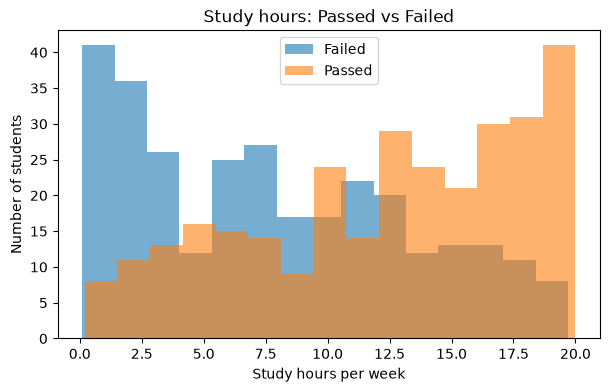

In [8]:
plt.figure(figsize=(7, 4))
plt.hist(df[df["passed"] == 0]["study_hours"], alpha=0.6, label="Failed", bins=15)
plt.hist(df[df["passed"] == 1]["study_hours"], alpha=0.6, label="Passed", bins=15)
plt.xlabel("Study hours per week")
plt.ylabel("Number of students")
plt.title("Study hours: Passed vs Failed")
plt.legend()
plt.show()


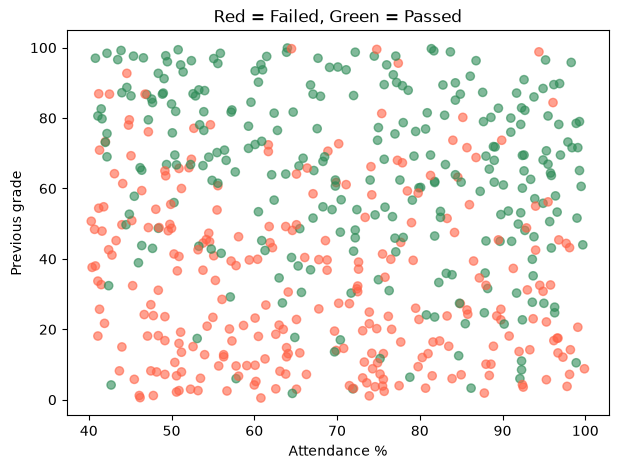

In [9]:
colors = df["passed"].map({0: "tomato", 1: "seagreen"})

plt.figure(figsize=(7, 5))
plt.scatter(df["attendance"], df["previous_grade"], c=colors, alpha=0.6)
plt.xlabel("Attendance %")
plt.ylabel("Previous grade")
plt.title("Red = Failed, Green = Passed")
plt.show()

In [15]:
df.shape

(600, 5)

In [13]:
X= df.drop("passed", axis=1)
Y=df["passed"]

print("Features: " ,list(X.columns))

Features:  ['study_hours', 'attendance', 'previous_grade', 'assignments_done']


In [18]:
from sklearn.model_selection import train_test_split
X_train,X_test,Y_train,Y_test = train_test_split(X, Y, test_size= 0.2,random_state=42)

print("Train: ", X_train.shape)
print("Test: " ,X_test.shape)


Train:  (480, 4)
Test:  (120, 4)


In [23]:
medians=    X_train.median()

X_train= X_train.fillna(medians)
X_test=X_test.fillna(medians)

print("missing values in train : ", X_train.isna().sum())
print("========================================================")
print("missing values in test : ", X_test.isna().sum())




missing values in train :  study_hours         0
attendance          0
previous_grade      0
assignments_done    0
dtype: int64
missing values in test :  study_hours         0
attendance          0
previous_grade      0
assignments_done    0
dtype: int64


In [24]:
from sklearn.ensemble import RandomForestClassifier

model=RandomForestClassifier(random_state=42)
model.fit(X_train,Y_train)

print("done")

done


In [26]:
prediction = model.predict(X_test)

compression= pd.DataFrame({
    "REAL: ": Y_test.values[:10],
    "PREDECTED: ":prediction[:10],
}
)

compression

,REAL:,PREDECTED:
0,0,0
1,1,1
2,1,0
3,1,1
4,0,0
5,0,0
6,0,0
7,1,1
8,0,0
9,1,1


In [34]:
from sklearn.metrics import accuracy_score

accuracy=accuracy_score(Y_test,prediction)

print(f"accuracy: {accuracy: .2%} " )

accuracy:  80.83% 


In [37]:
from sklearn.metrics import classification_report

print(classification_report(Y_test,prediction))



              precision    recall  f1-score   support

           0       0.80      0.84      0.82        62
           1       0.82      0.78      0.80        58

    accuracy                           0.81       120
   macro avg       0.81      0.81      0.81       120
weighted avg       0.81      0.81      0.81       120



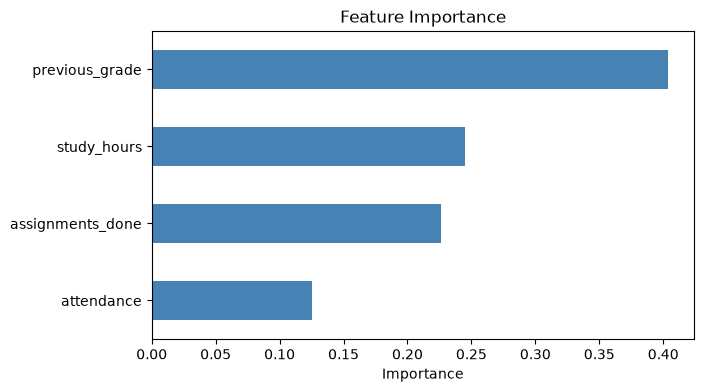

In [42]:
importances = pd.Series(model.feature_importances_, index=X.columns).sort_values()

plt.figure(figsize=(7, 4))
importances.plot(kind="barh", color="steelblue")
plt.title("Feature Importance")
plt.xlabel("Importance")
plt.show()